In [11]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, os
from scipy import stats

df = pd.read_csv("/kaggle/input/datasets/lainguyn123/student-performance-factors/StudentPerformanceFactors.csv")
os.makedirs("/kaggle/working/charts", exist_ok=True)
print(df.shape)
df.head()

(6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [12]:
for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        print(os.path.join(root, f))

/kaggle/input/datasets/lainguyn123/student-performance-factors/StudentPerformanceFactors.csv


In [14]:
print(df.isna().sum())
print(df[df["Exam_Score"] > 100])
df = df[df["Exam_Score"] <= 100]
df[["Hours_Studied","Attendance","Exam_Score","Sleep_Hours","Previous_Scores"]].describe()

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64
      Hours_Studied  Attendance Parental_Involvement Access_to_Resources  \
1525             27          98                  Low              Medium   

     Extracurricular_Activities  Sleep_Hours  Previous_Scores  \
1525                        Yes            6               93   

     Motivation_Level Internet_Access  Tuto

,Hours_Studied,Attendance,Exam_Score,Sleep_Hours,Previous_Scores
count,6606.000000,6606.000000,6606.000000,6606.000000,6606.000000
mean,19.974266,79.974720,67.230548,7.029216,75.067817
std,5.990424,11.546219,3.868502,1.468177,14.399184
min,1.000000,60.000000,55.000000,4.000000,50.000000
25%,16.000000,70.000000,65.000000,6.000000,63.000000
50%,20.000000,80.000000,67.000000,7.000000,75.000000
75%,24.000000,90.000000,69.000000,8.000000,88.000000
max,44.000000,100.000000,100.000000,10.000000,100.000000


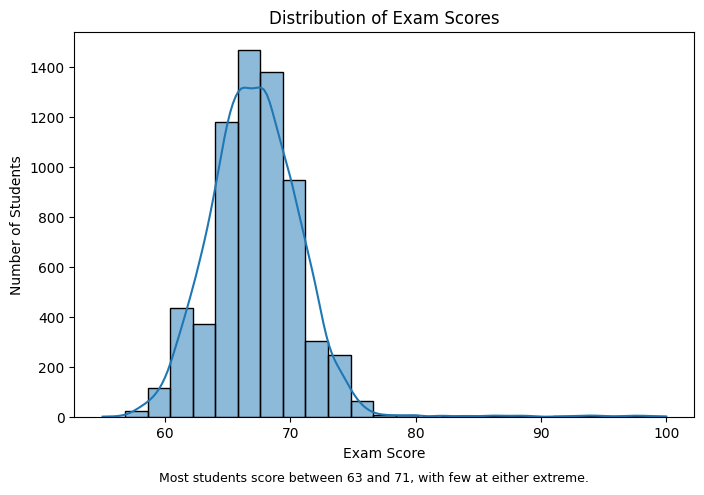

In [28]:
plt.figure(figsize=(8,5))
sns.histplot(df["Exam_Score"], kde=True, bins=25)
plt.title("Distribution of Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")
plt.figtext(0.5, -0.02, "Most students score between 63 and 71, with few at either extreme.", ha="center", fontsize=9)
plt.savefig("/kaggle/working/charts/01_score_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

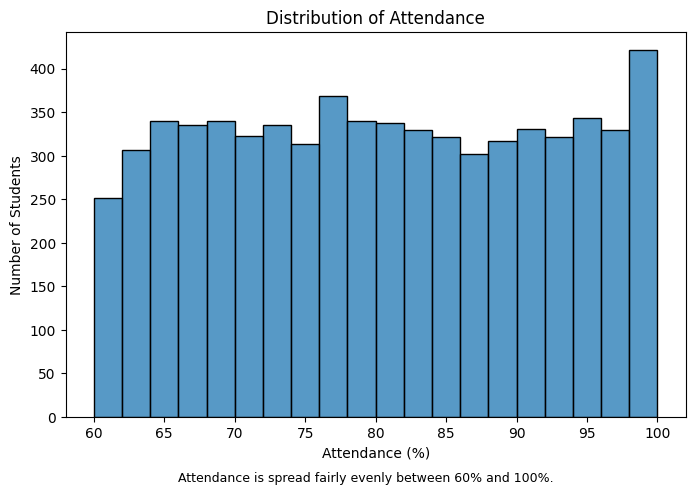

In [18]:
plt.figure(figsize=(8,5))
sns.histplot(df["Attendance"], bins=20)
plt.title("Distribution of Attendance")
plt.xlabel("Attendance (%)")
plt.ylabel("Number of Students")
plt.figtext(0.5, -0.02, "Attendance is spread fairly evenly between 60% and 100%.", ha="center", fontsize=9)
plt.savefig("/kaggle/working/charts/02_attendance_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

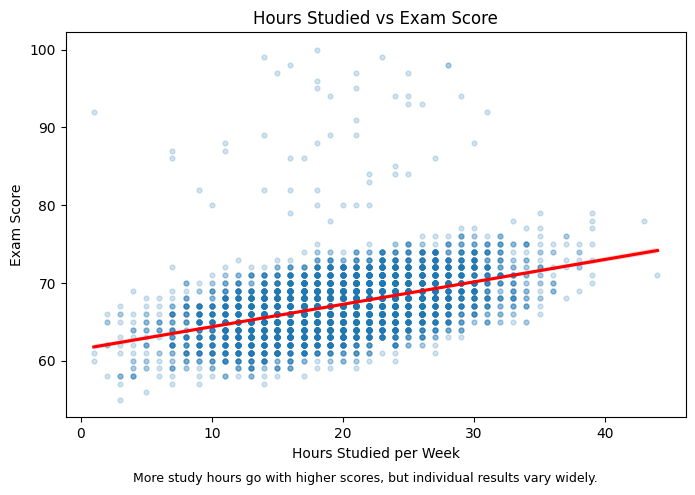

In [19]:
plt.figure(figsize=(8,5))
sns.regplot(data=df, x="Hours_Studied", y="Exam_Score",
            scatter_kws={"alpha":0.2, "s":12}, line_kws={"color":"red"})
plt.title("Hours Studied vs Exam Score")
plt.xlabel("Hours Studied per Week")
plt.ylabel("Exam Score")
plt.figtext(0.5, -0.02, "More study hours go with higher scores, but individual results vary widely.", ha="center", fontsize=9)
plt.savefig("/kaggle/working/charts/03_hours_vs_score.png", dpi=150, bbox_inches="tight")
plt.show()

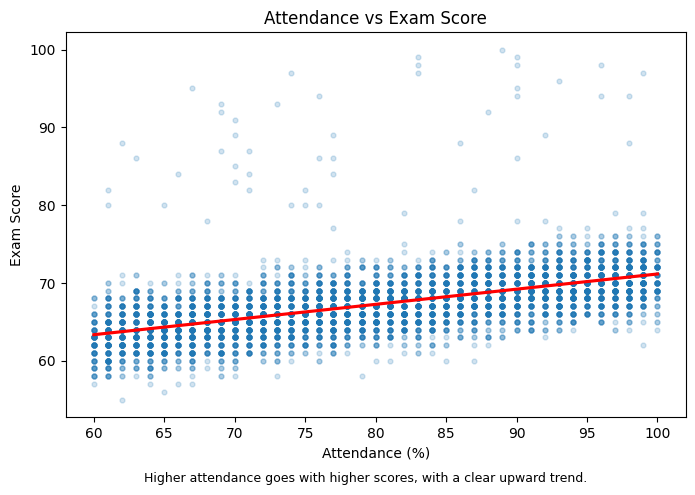

In [20]:
plt.figure(figsize=(8,5))
sns.regplot(data=df, x="Attendance", y="Exam_Score",
            scatter_kws={"alpha":0.2, "s":12}, line_kws={"color":"red"})
plt.title("Attendance vs Exam Score")
plt.xlabel("Attendance (%)")
plt.ylabel("Exam Score")
plt.figtext(0.5, -0.02, "Higher attendance goes with higher scores, with a clear upward trend.", ha="center", fontsize=9)
plt.savefig("/kaggle/working/charts/04_attendance_vs_score.png", dpi=150, bbox_inches="tight")
plt.show()

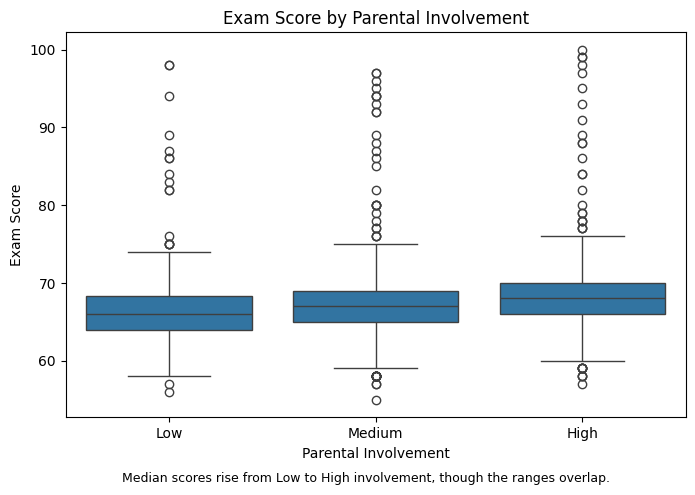

In [21]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="Parental_Involvement", y="Exam_Score", order=["Low","Medium","High"])
plt.title("Exam Score by Parental Involvement")
plt.xlabel("Parental Involvement")
plt.ylabel("Exam Score")
plt.figtext(0.5, -0.02, "Median scores rise from Low to High involvement, though the ranges overlap.", ha="center", fontsize=9)
plt.savefig("/kaggle/working/charts/05_score_by_parental_involvement.png", dpi=150, bbox_inches="tight")
plt.show()

In [22]:
print(df["Exam_Score"].describe())
print(df.groupby("Parental_Involvement")["Exam_Score"].median())
print(df[["Hours_Studied","Attendance","Exam_Score"]].corr().round(2))

count    6606.000000
mean       67.230548
std         3.868502
min        55.000000
25%        65.000000
50%        67.000000
75%        69.000000
max       100.000000
Name: Exam_Score, dtype: float64
Parental_Involvement
High      68.0
Low       66.0
Medium    67.0
Name: Exam_Score, dtype: float64
               Hours_Studied  Attendance  Exam_Score
Hours_Studied           1.00       -0.01        0.45
Attendance             -0.01        1.00        0.58
Exam_Score              0.45        0.58        1.00


In [25]:
print(os.listdir("/kaggle/working/charts"))

['04_attendance_vs_score.png', '02_attendance_distribution.png', 'score_distribution.png', '05_score_by_parental_involvement.png', '03_hours_vs_score.png']
